# 6. Hafta: Stochastic Game of Life

Bu hafta Game of Life'a rastgele ölüm ekleyip sistemin nasıl değiştiğine baktım. Önce 6. hafta alıştırmalarını yaptım, sonra ölümlerin belli bölgelerde kümelenmesi durumunu da denedim.

Temel kural aynı. Önce normal Game of Life adımı çalışıyor, ardından canlı hücreler `μ` olasılığıyla ölebiliyor. İlk modelde ölümler birbirinden bağımsız. İkinci modelde ise yakın hücrelerin birlikte ölmesi daha olası.

Son kısımda 60, 80, 100 ve 200 boyutlarında, 3.000 adımlık deneyleri karşılaştırdım.

## 1. Model ve önceki haftalarla bağlantısı

İlk dört haftada temel hücresel otomat kurallarını, sınıflandırmayı, başlangıç koşullarına duyarlılığı ve Conway'in Game of Life modelini inceledim. Beşinci haftada rastgele başlangıçlardan yola çıkarak yoğunluk ve etkinliği çok sayıda deneyde ölçtüm.

Bu hafta başlangıç yoğunluğunu sabit tutup güncelleme kuralından sonraki rastgele ölümü değiştirdim. Önce standart Game of Life kuralı uygulanıyor. Daha sonra hayatta kalan hücreler $\mu$ olasılığıyla siliniyor.

$$G_{t+1}=D_{\mu}(F_{\mathrm{Life}}(G_t))$$

- $\mu=0$ olduğunda standart Game of Life çalışıyor.
- $\mu=1$ olduğunda ilk güncellemenin ardından canlı hücre kalmıyor.
- Boş ızgara soğurucu bir durum. Sonraki adımlarda kendiliğinden yeniden canlı hücre doğmuyor.

Kenarlar periyodik bağlı. Yani ızgaranın bir kenarından çıkan komşuluk öteki kenarda devam ediyor.

### Model hakkında tahminlerim

1. **Ölüm olasılığı arttıkça ne olur?** Yoğunluğun genel olarak azalmasını bekliyorum. Etkinliğin her aralıkta aynı şekilde azalması gerekmiyor. Bazı hücreler daha fazla değişebilir ama sistem boşaldığında etkinlik sıfıra iner.
2. **Küçük bir $\mu$ ile sabit blok korunur mu?** Kesin olarak korunmaz. Küçük de olsa her güncellemede rastgele silinme ihtimali var.
3. **Etkinlik sıfır, yoğunluk pozitif olabilir mi?** Evet. Sabit bir yapı varsa hücreler canlı kaldığı halde o adımda değişim olmayabilir. $\mu>0$ iken sonraki adımda rastgele ölüm gerçekleşebilir.
4. **Neden tekrar yapıyoruz?** Hem farklı başlangıç ızgaraları hem de sonraki rastgele ölüm çekilişleri sonuçları değiştirebildiği için tek deney yeterli olmaz.

Bu tahmin notlarını deneylerin tamamlandığı sürümü düzenlerken ekledim. Deney öncesinde yazılmış kayıtlar olarak değerlendirmiyorum.


## 2. Kurulum

Izgarada `1` canlı, `0` ölü hücre demek. Her adımda önce B3/S23 kuralını, sonra rastgele ölümü uyguluyorum. `steps` sayısına başlangıç durumu da dahil.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

plt.rcParams["figure.dpi"] = 110

def count_neighbors(grid):
    neighbors = np.zeros_like(grid, dtype=np.uint8)
    for i in (-1, 0, 1):
        for j in (-1, 0, 1):
            if i != 0 or j != 0:
                neighbors += np.roll(np.roll(grid, i, axis=0), j, axis=1)
    return neighbors

def update_life(grid):
    neighbors = count_neighbors(grid)
    birth = (grid == 0) & (neighbors == 3)
    survive = (grid == 1) & ((neighbors == 2) | (neighbors == 3))
    return (birth | survive).astype(np.uint8)

def random_grid(size, p0, rng):
    return (rng.random((size, size)) < p0).astype(np.uint8)

def density_time_series(history):
    return history.mean(axis=(1, 2))

def activity_time_series(history):
    return (history[1:] != history[:-1]).mean(axis=(1, 2))

def late_time_average(values, window):
    return float(np.mean(values[-window:]))

print("Kurulum tamam.")

Kurulum tamam.


### Standart Life kontrolü

Hocanın orijinal defterinde geçen `simulate_life` fonksiyonunu da ayrı bir kontrol olarak ekledim. Bu fonksiyon rastgele ölüm uygulamıyor. Böylece $\mu=0$ ile standart Game of Life sonuçlarının aynı olup olmadığını ölçebiliyorum.


In [ ]:
def simulate_life(initial_grid, steps):
    initial_grid = np.asarray(initial_grid, dtype=np.uint8)
    history = np.zeros((steps, *initial_grid.shape), dtype=np.uint8)
    history[0] = initial_grid
    for t in range(1, steps):
        history[t] = update_life(history[t - 1])
    return history


## 3. Alıştırmalar

Beş fonksiyon yazdım. Sırayla rastgele ölümü uyguluyor, bir sonraki Life durumunu hesaplıyor, simülasyonu çalıştırıyor, sönme zamanını buluyor ve aynı deneyi tekrar ediyorlar.

### Alıştırmaların görevi

- **Alıştırma 1, `apply_random_death`:** Canlı hücreleri rastgele siliyor. Giriş ızgarasını değiştirmiyor.
- **Alıştırma 2, `update_noisy_life`:** Önce B3/S23 kuralını, ardından rastgele ölümü uyguluyor.
- **Alıştırma 3, `simulate_noisy_life`:** Başlangıç karesi dahil istenen sayıda kare oluşturuyor ve aynı rastgele sayı üretecini kullanıyor.
- **Alıştırma 4, `first_extinction_time`:** Tamamen boşalan ilk karenin indeksini döndürüyor. Sönme yoksa `None` döndürüyor.
- **Alıştırma 5, `run_noisy_ensemble`:** Her tekrarda yeni başlangıç ve yeni rastgele dinamik kullanıyor. Son dönemin yoğunluğunu, etkinliğini ve sönme zamanını kaydediyor.

Beş fonksiyonun mevcut kodunu değiştirmedim. Her birinin mantığını bu açıklamalarda ayrı olarak gösterdim.


In [2]:
# Canlı hücreleri mu olasılığıyla siliyorum.
def apply_random_death(grid, mu, rng):
    if not 0 <= mu <= 1:
        raise ValueError("mu 0 ile 1 arasında olmalı")
    draws = rng.random(grid.shape)
    return ((grid == 1) & (draws >= mu)).astype(np.uint8)

# Önce Life adımı, sonra rastgele ölüm.
def update_noisy_life(grid, mu, rng):
    next_grid = update_life(grid)
    return apply_random_death(next_grid, mu, rng)

# Zaman boyunca ızgaraları kaydediyorum.
def simulate_noisy_life(initial_grid, steps, mu, rng):
    if steps < 2:
        raise ValueError("steps en az 2 olmalı")
    history = np.zeros((steps, *initial_grid.shape), dtype=np.uint8)
    history[0] = initial_grid
    for t in range(1, steps):
        history[t] = update_noisy_life(history[t - 1], mu, rng)
    return history

# İlk sönme zamanını buluyorum.
def first_extinction_time(history):
    for t, frame in enumerate(history):
        if not frame.any():
            return t
    return None

# Aynı deneyi farklı başlangıçlarla tekrarlıyorum.
def run_noisy_ensemble(size, p0, steps, runs, late_window, mu, rng):
    if runs < 2 or steps < 2 or not 1 <= late_window <= steps - 1:
        raise ValueError("Parametreleri kontrol et")
    late_rho = np.zeros(runs)
    late_activity = np.zeros(runs)
    extinction_times = np.full(runs, np.nan)
    for k in range(runs):
        initial = random_grid(size, p0, rng)
        history = simulate_noisy_life(initial, steps, mu, rng)
        late_rho[k] = late_time_average(density_time_series(history), late_window)
        late_activity[k] = late_time_average(activity_time_series(history), late_window)
        t = first_extinction_time(history)
        if t is not None:
            extinction_times[k] = t
    return late_rho, late_activity, extinction_times

def summarize_ensemble(rho, activity, times):
    runs = len(rho)
    return {
        "rho_mean": float(np.mean(rho)),
        "rho_se": float(np.std(rho, ddof=1) / np.sqrt(runs)),
        "activity_mean": float(np.mean(activity)),
        "activity_se": float(np.std(activity, ddof=1) / np.sqrt(runs)),
        "extinction_fraction": float(np.isfinite(times).mean()),
    }

## 4. Testler

Özellikle `μ = 0` ve `μ = 1` durumlarını kontrol ettim. Aynı rastgele sayı tohumu kullanıldığında aynı sonucu almam da gerekiyor.

In [3]:
g = np.array([[1,0,1],[1,1,0]], dtype=np.uint8)
assert np.array_equal(apply_random_death(g, 0, np.random.default_rng(1)), g)
assert not apply_random_death(g, 1, np.random.default_rng(1)).any()
r = np.random.default_rng(84).random(g.shape)
assert np.array_equal(apply_random_death(g, .4, np.random.default_rng(84)), ((g == 1) & (r >= .4)).astype(np.uint8))
b = np.zeros((7,7), dtype=np.uint8)
b[3,2:5] = 1
assert np.array_equal(update_noisy_life(b, 0, np.random.default_rng(1)), update_life(b))
assert not update_noisy_life(b, 1, np.random.default_rng(1)).any()
h = simulate_noisy_life(b, 10, 0, np.random.default_rng(1))
assert h.shape == (10,7,7)
assert np.array_equal(h[1], update_life(b))
assert first_extinction_time(np.array([g, np.zeros_like(g)])) == 1
assert first_extinction_time(np.array([g, g])) is None
q = run_noisy_ensemble(6, 1, 4, 3, 2, 1, np.random.default_rng(7))
assert np.allclose(q[0], 0) and np.array_equal(q[2], [1,1,1])
print("✓ Beş alıştırmanın temel testleri geçti")

✓ Beş alıştırmanın temel testleri geçti


### Ek alıştırma testleri

Hocanın şablonunda girişin değişmemesi, aynı rastgele tohumun aynı sonucu vermesi ve $\mu$ uç durumları da kontrol ediliyor. Temel testlere ek olarak bunlara baktım.


In [ ]:
test_izgara = np.array([[1, 0, 1], [1, 1, 0]], dtype=np.uint8)
test_kopya = test_izgara.copy()
apply_random_death(test_izgara, 0.4, np.random.default_rng(84))
assert np.array_equal(test_izgara, test_kopya)

test_baslangic = np.zeros((7, 7), dtype=np.uint8)
test_baslangic[3, 2:5] = 1
h0 = simulate_noisy_life(test_baslangic, 5, 0, np.random.default_rng(12))
assert np.array_equal(h0, simulate_life(test_baslangic, 5))

h1 = simulate_noisy_life(test_baslangic, 5, 1, np.random.default_rng(12))
assert not h1[1:].any()

ha = simulate_noisy_life(test_baslangic, 5, 0.2, np.random.default_rng(99))
hb = simulate_noisy_life(test_baslangic, 5, 0.2, np.random.default_rng(99))
assert np.array_equal(ha, hb)

r1 = run_noisy_ensemble(12, 0.35, 20, 4, 5, 0.02, np.random.default_rng(77))
r2 = run_noisy_ensemble(12, 0.35, 20, 4, 5, 0.02, np.random.default_rng(77))
for a, b in zip(r1, r2):
    assert np.array_equal(a, b, equal_nan=True)

print("Ek alıştırma testleri geçti.")


### Sönme ve istatistiksel ölçümler

İlk sönme zamanı $\tau_{\mathrm{ext}}$, yoğunluğun ilk kez sıfıra indiği zamandır.

$$\tau_{\mathrm{ext}}=\min\{t: \rho(t)=0\}$$

Bir deney 3.000 adımda sönmemişse onun gerçek sönme zamanını bilmiyoruz. Bu, sonsuza kadar yaşayacağı anlamına gelmiyor. Sonlu boyutlu bir ızgarada $\mu>0$ ve bağımsız ölüm için her adımda bütün canlı hücrelerin birden silinme olasılığı sıfırdan büyüktür. Bu nedenle sonsuz zaman sınırında sonunda sönme olasılığı 1 olur. Ama bunun gerçekleşmesi çok uzun sürebilir.

**Ortalama**, tekrarların tipik sonucunu veriyor. **Standart sapma (SD)** deneyler arasındaki farkı gösteriyor. **Standart hata (SE)** ise ortalamayı tahmin ederken oluşan belirsizlikle ilgili.

$$\mathrm{SE}=\frac{\mathrm{SD}}{\sqrt M}$$

Mevcut ana grafiklerdeki hata çubukları standart sapma değil, standart hata.


In [ ]:
# Standart sapma ve standart hatayı ayrıca gösteriyorum.
def ayrintili_ozet(rho, activity, times):
    sonuc = summarize_ensemble(rho, activity, times).copy()
    sonuc['rho_sd'] = float(np.std(rho, ddof=1))
    sonuc['activity_sd'] = float(np.std(activity, ddof=1))
    return sonuc

ornek = ayrintili_ozet([0.0, 1.0], [0.0, 1.0], [1.0, np.nan])
assert ornek['extinction_fraction'] == 0.5
assert ornek['rho_sd'] > ornek['rho_se']
print("Standart sapma ve standart hata kontrolü geçti.")


## 5. İlk deneyler

Önce daha kısa bir pilot deney yaptım. Sonra farklı `μ` değerlerini karşılaştırdım. Burada 800 kare ve her değer için 16 tekrar kullandım.

Tekrarlar sırasında `L`, başlangıç yoğunluğu ve adım sayısı aynı. Sadece `μ` değişiyor. Daha uzun süre izlemek faydalı olsa da tekrar sayısı da önemli.

In [4]:
# Deneyde kullandığım değerler.
RUN_PILOT = True
RUN_MAIN = True
L = 60
p0 = 0.35
pilot_steps = 350
pilot_runs = 6
main_steps = 800
main_runs = 16
late_window = 160
mu_values = [0, .002, .005, .01, .02, .03, .04, .06, .10, .20, 1.0]

pilot_results = {}
if RUN_PILOT:
    rng = np.random.default_rng(202606)
    for mu in [0, .01, .02, .05, .10, 1.0]:
        samples = run_noisy_ensemble(40, p0, pilot_steps, pilot_runs, 80, mu, rng)
        pilot_results[mu] = summarize_ensemble(*samples)
    print("Pilot çalıştı:", len(pilot_results), "mu değeri")

main_results = {}
if RUN_MAIN:
    rng = np.random.default_rng(20260606)
    start = time.perf_counter()
    for mu in mu_values:
        samples = run_noisy_ensemble(L, p0, main_steps, main_runs, late_window, mu, rng)
        main_results[mu] = summarize_ensemble(*samples)
        print(f"mu={mu:0.3f} yoğunluk={main_results[mu]['rho_mean']:.4f} "
              f"etkinlik={main_results[mu]['activity_mean']:.4f} "
              f"sönme={main_results[mu]['extinction_fraction']:.2f}")
    print("Ana tarama süresi (s):", round(time.perf_counter()-start, 1))

Pilot çalıştı: 6 mu değeri


mu=0.000 yoğunluk=0.0475 etkinlik=0.0269 sönme=0.00


mu=0.002 yoğunluk=0.0206 etkinlik=0.0094 sönme=0.00


mu=0.005 yoğunluk=0.0099 etkinlik=0.0012 sönme=0.00


mu=0.010 yoğunluk=0.0071 etkinlik=0.0001 sönme=0.00


...

mu=0.040 yoğunluk=0.0001 etkinlik=0.0000 sönme=0.94


mu=0.060 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00


mu=0.100 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00


mu=0.200 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00


mu=1.000 yoğunluk=0.0000 etkinlik=0.0000 sönme=1.00
Ana tarama süresi (s): 16.9


### Pilot deneyin yorumu

Pilot deneyde $L=40$, $T=350$ ve $M=6$ kullandım. Ölüm olasılıklarını 0, 0,01, 0,02, 0,05, 0,10 ve 1 olarak karşılaştırdım.

- Sıfıra yakın küçük $\mu$ değerlerinde de önemli değişimler görülebileceği için ana deneyde bu bölgeyi daha sık taradım.
- $\mu=0$ için normal Life davranışı bekleniyor. $\mu=1$ için ilk güncellemeden sonra bütün canlı hücreler siliniyor.
- Altı tekrar sonuçları görmek için yeterli bir başlangıç ancak güçlü bir istatistiksel sonuç için az.
- Pilotun ayrı süresini kaydetmedim. Ana taramanın kayıtlı çalışma süresi yaklaşık 16,9 saniyeydi.

Ana deneyde $L=60$, $T=800$, $M=16$ kullandım. Başlangıç olasılığı $p_0=0,35$ olarak sabit kaldı. Bu deneyin amacı değişik $\mu$ değerlerini aynı koşullarda karşılaştırmak.


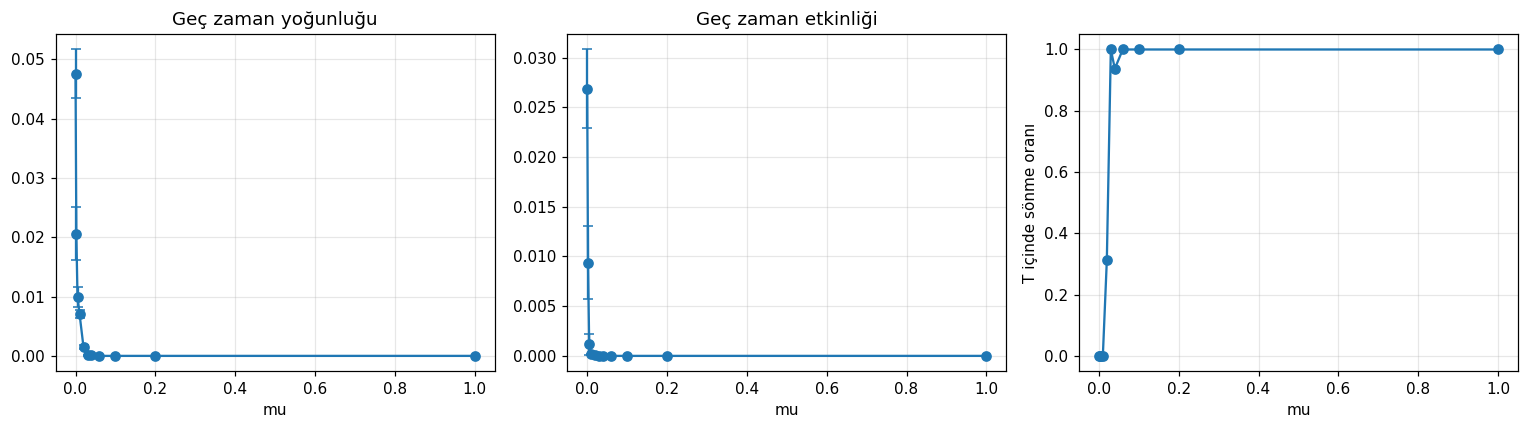

In [5]:
if main_results:
    fig, axes = plt.subplots(1, 3, figsize=(14,4))
    for ax, key, se, title in [
        (axes[0], 'rho_mean', 'rho_se', 'Geç zaman yoğunluğu'),
        (axes[1], 'activity_mean', 'activity_se', 'Geç zaman etkinliği'),
    ]:
        ax.errorbar(mu_values, [main_results[m][key] for m in mu_values],
                    yerr=[main_results[m][se] for m in mu_values], fmt='o-', capsize=3)
        ax.set(xlabel='mu', title=title)
    axes[2].plot(mu_values, [main_results[m]['extinction_fraction'] for m in mu_values], 'o-')
    axes[2].set(xlabel='mu', ylabel='T içinde sönme oranı')
    for ax in axes:
        ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()

### Ana deney sonuç tablosu

Hocanın şablonunda grafiklerden sonra sayısal bir tablo da bulunuyor. Aşağıdaki hücre mevcut `main_results` verilerini yazdırıyor. Yeni simülasyon başlatmıyor.


In [ ]:
print("mu    yoğunluk    yoğunluk SE    etkinlik    etkinlik SE    sönme oranı")
for deger in mu_values:
    r = main_results[deger]
    print(f"{deger:0.3f}  {r['rho_mean']:0.5f}  {r['rho_se']:0.5f}  "
          f"{r['activity_mean']:0.5f}  {r['activity_se']:0.5f}  "
          f"{r['extinction_fraction']:0.2f}")


### Ana deneyin yorumları

1. **Beşinci hafta ile karşılaştırma:** $\mu=0$ değerinde güncelleme kuralı aynıdır. Ancak önceki haftada farklı gözlem süreleri ve rastgele başlangıçlar kullanıldığı için sayısal sonuçların tamamen aynı olması gerekmiyor.
2. **Yoğunluğun azalması:** Ana taramada $\mu=0$ için geç yoğunluk yaklaşık 0,0475. $\mu=0,005$ için 0,0099, $\mu=0,02$ için yaklaşık 0,0015 oldu. Bu koşullarda belirgin azalma gördüm.
3. **Sönme oranı:** $\mu=0,02$ için 16 tekrarın 5'i söndü. $\mu=0,03$ için 16 tekrarın tamamı söndü. $\mu=0,04$ için 15'i söndü. Bu fark, sonlu sayıda tekrarın rastgele dalgalanmasını gösteriyor.
4. **En yüksek yoğunluk ve sönme:** Yoğunluğun yüksek olduğu değer ile sönmenin sıklaştığı değer aynı şey değil. Ölçtüğüm iki farklı özellik.
5. **Hata çubukları:** Grafiklerde ortalamanın standart hatası var. Standart sapma kullansaydım ortalamadan çok deneyler arasındaki değişkenliği gösterirdim.
6. **Gözlem süresi:** 800 karede sönmeyen bir deneyin sonraki adımlarda da canlı kalacağını söyleyemem.

Bu değerler yalnızca 800 karelik ana taramaya ait. Sonraki 3.000 adımlık araştırmayı ayrı olarak değerlendirdim.


## 6. Aynı başlangıçla üç deney

Başlangıç ızgarasını değiştirmeden üç farklı rastgele sayı tohumu kullandım. Böylece sonuçların ne kadar değişebildiğini görmek istedim.

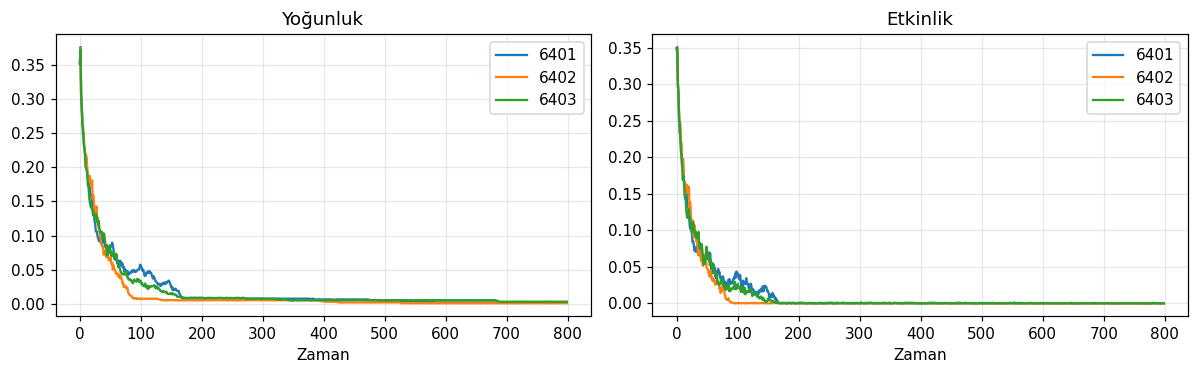

In [6]:
fixed_initial = random_grid(L, p0, np.random.default_rng(6400))
fig, axes = plt.subplots(1, 2, figsize=(11,3.5))
for seed in (6401, 6402, 6403):
    h = simulate_noisy_life(fixed_initial, main_steps, .02, np.random.default_rng(seed))
    axes[0].plot(density_time_series(h), label=str(seed))
    axes[1].plot(activity_time_series(h), label=str(seed))
axes[0].set(title='Yoğunluk', xlabel='Zaman')
axes[1].set(title='Etkinlik', xlabel='Zaman')
for ax in axes:
    ax.legend()
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

### Aynı başlangıç deneyini yorumlama

Üç deneyde aynı başlangıç ızgarasını kullandım. Yalnızca rastgele ölüm için kullanılan sayı tohumlarını değiştirdim. Eğriler farklılaşırsa bu farkı başlangıç koşuluna değil, zaman içindeki rastgele ölüm çekilişlerine bağlıyorum. Beşinci haftadaki tekrarlar ise farklı rastgele başlangıçlar da içeriyordu.


## 7. Adım sayısı fark yaratıyor mu?

350 ve 1.000 karede sönme oranlarını karşılaştırdım. Bunun için aynı 1.000 karelik koşuların ilk 350 karesini de ayrıca kontrol ettim. Böylece farklı başlangıçların etkisi karışmıyor.

In [7]:
robust_mu = .02
robust_runs = 12
robust_steps = 1000
ext_350 = []
ext_1000 = []
rng = np.random.default_rng(719)
for k in range(robust_runs):
    initial = random_grid(L, p0, rng)
    history = simulate_noisy_life(initial, robust_steps, robust_mu, rng)
    ext_350.append(first_extinction_time(history[:350]) is not None)
    ext_1000.append(first_extinction_time(history) is not None)
print('350 adımda sönme:', np.mean(ext_350))
print('1000 adımda sönme:', np.mean(ext_1000))
assert np.mean(ext_1000) >= np.mean(ext_350)

350 adımda sönme: 0.0
1000 adımda sönme: 0.4166666666666667


### 150 ve 350 adımlık ek sağlamlık kontrolü

Hocanın şablonunda istenen 150 ve 350 kare karşılaştırmasını da aynı başlangıç ve aynı rastgele çekilişler üzerinden ölçüyorum. Önceki 350 ve 1.000 kare karşılaştırmamı değiştirmedim.


In [ ]:
kontrol_rng = np.random.default_rng(1719)
sonme_150 = []
sonme_350 = []
for tekrar in range(12):
    ilk = random_grid(L, p0, kontrol_rng)
    gecmis = simulate_noisy_life(ilk, 350, 0.02, kontrol_rng)
    sonme_150.append(first_extinction_time(gecmis[:150]) is not None)
    sonme_350.append(first_extinction_time(gecmis) is not None)

print("150 karede sönme oranı:", np.mean(sonme_150))
print("350 karede sönme oranı:", np.mean(sonme_350))
assert np.mean(sonme_350) >= np.mean(sonme_150)


Bu kontrolün amacı, gözlem süresini uzattığımda sönme oranının nasıl değiştiğini görmek. Aynı deneyleri iki farklı sürede karşılaştırdığım için daha uzun sürede daha az sönme kaydetmem beklenmez. On iki tekrarın belirsizliğini de göz önünde bulundurmam gerekiyor.


## 8. Bağımsız ve kümelenmiş ölüm

Aklıma gelen soru şu oldu: Hücrelerin ölüm olasılığı aynı kalsa ama ölümler yakın bölgelerde kümelense sistemin davranışı değişir mi?

Bunu denemek için ikinci modelde rastgele sayılara Gauss filtresi uyguladım. Filtre, yakın konumlardaki değerleri birbirine benzetiyor. Sonra değerleri 0 ile 1 arasına dönüştürüp aynı `μ` eşiğini kullandım.

Böylece her hücrenin tek başına ölüm olasılığı aynı kalıyor, fakat ölümlerin yerleri birbirinden bağımsız olmuyor. Bu, her tekrarda ölen hücre sayısının kesinlikle aynı olacağı anlamına gelmiyor.

In [8]:
from scipy.special import ndtr

def correlated_death_mask(shape, mu, sigma, rng):
    if not 0 <= mu <= 1:
        raise ValueError('mu 0 ile 1 arasında')
    if sigma <= 0:
        return rng.random(shape) < mu
    # Önce bağımsız rastgele sayılar üretiyorum.
    noise = rng.standard_normal(shape)
    field = gaussian_filter(noise, sigma=sigma, mode='wrap')
    # Filtre sonrası standart sapmayı hesaplıyorum.
    weights = np.zeros(shape)
    weights[0, 0] = 1
    kernel = gaussian_filter(weights, sigma=sigma, mode='wrap')
    field = field / np.sqrt(np.sum(kernel ** 2))
    uniforms = ndtr(field)
    return uniforms < mu

def update_correlated_life(grid, mu, sigma, rng):
    next_grid = update_life(grid)
    mask = correlated_death_mask(grid.shape, mu, sigma, rng)
    next_grid[mask] = 0
    return next_grid

def simulate_correlated_life(initial, steps, mu, sigma, rng):
    history = np.zeros((steps, *initial.shape), dtype=np.uint8)
    history[0] = initial
    for t in range(1, steps):
        history[t] = update_correlated_life(history[t - 1], mu, sigma, rng)
    return history

# Uç durumları kontrol ediyorum.
assert np.array_equal(update_correlated_life(b, 0, 2, np.random.default_rng(1)), update_life(b))
assert not update_correlated_life(b, 1, 2, np.random.default_rng(1)).any()
assert not update_correlated_life(b, 1, 0, np.random.default_rng(1)).any()
print('✓ Korelasyonlu modelin uç durum testleri geçti')

✓ Korelasyonlu modelin uç durum testleri geçti


### 8.1 Ölüm olasılığı kontrolü

İki modelde ortalama ölüm oranının `μ` değerine yakın olup olmadığına baktım. Ayrıca yan yana iki hücrenin birlikte ölme oranını ölçtüm. Kümelenmiş modelde bu değerin daha yüksek olmasını bekliyorum.

In [9]:
test_mu = .10
n_fields = 300
rates = []
pairs = []
for sigma in (0, 2.0):
    rng = np.random.default_rng(202610 + int(sigma * 10))
    death_sum = 0
    pair_sum = 0
    for k in range(n_fields):
        dead = correlated_death_mask((40,40), test_mu, sigma, rng)
        death_sum += dead.mean()
        pair_sum += (dead & np.roll(dead, 1, axis=0)).mean()
    rates.append(death_sum / n_fields)
    pairs.append(pair_sum / n_fields)
print('Ölüm oranları (bağımsız/kümelenmiş):', np.round(rates, 4))
print('Komşu iki hücrenin birlikte ölmesi:', np.round(pairs, 4))
assert abs(rates[0] - test_mu) < .02 and abs(rates[1] - test_mu) < .02
assert pairs[1] > pairs[0]
print('✓ Marjinal oran kontrolü ve kümelenme kontrolü geçti')

Ölüm oranları (bağımsız/kümelenmiş): [0.0999 0.097 ]
Komşu iki hücrenin birlikte ölmesi: [0.01   0.0733]
✓ Marjinal oran kontrolü ve kümelenme kontrolü geçti


### İlintili ölümün ölçülmesi

$\mu=0,10$ ile yapılan maskelerde bağımsız modelin ortalama ölüm işaretleme oranı 0,0999, kümelenmiş modelinki 0,0970 olarak ölçüldü. İkisi de 0,10'a yakın.

Komşu iki konumun birlikte işaretlenmesi bağımsız modelde yaklaşık 0,0100, kümelenmiş modelde yaklaşık 0,0733 oldu. Bu sayılar, korelasyonun komşu ölümleri bir araya getirdiğini gösteriyor.

Gaussyen filtreye önce normal dağılımlı bağımsız sayılar veriyorum. Filtre bu sayıların uzaydaki ilişkisini değiştiriyor. Sonra alanı normalleştirip `ndtr` ile 0 ile 1 arasında düzgün dağılımlı değerlere dönüştürüyorum. Böylece tek hücre için olasılık aynı kalırken komşu ölüm olayları ilişki kazanıyor.

Bu maskelerdeki ölüm oranı ile Life güncellemesinden sonra gerçekten silinen canlı hücre oranı farklı ölçümlerdir. İlkinde bütün konumları, ikincisinde canlı kalmış konumları değerlendiriyoruz.


### 8.2 İki modeli karşılaştırma

Her tekrar için iki modelde aynı başlangıç ızgarasını kullandım. Ölüm için üretilen rastgele sayılar ise farklı. Bu sayede başlangıç farkını azaltıp ölümlerin dağılımını karşılaştırabiliyorum.

Kümelenmenin etkisini anlamak için hem yoğunluğa ve etkinliğe hem de sönme oranına baktım.

In [10]:
def compare_models(mu, sigma, size, steps, runs, window, seed):
    rng = np.random.default_rng(seed)
    results = {'independent': [], 'clustered': []}
    for k in range(runs):
        initial = random_grid(size, p0, rng)
        seed_ind = int(rng.integers(0, 2**32))
        seed_clu = int(rng.integers(0, 2**32))
        for name, s, local_seed in [('independent', 0, seed_ind),
                                    ('clustered', sigma, seed_clu)]:
            h = simulate_correlated_life(initial, steps, mu, s,
                                         np.random.default_rng(local_seed))
            extinction = first_extinction_time(h)
            results[name].append({
                'rho': late_time_average(density_time_series(h), window),
                'activity': late_time_average(activity_time_series(h), window),
                'tau': np.nan if extinction is None else extinction,
                'extinct': extinction is not None,
            })
    return results

# 1.000 kare, 16 tekrar, üç farklı mu değeri.
RUN_CORRELATION_STUDY = True
corr_size = 60
corr_steps = 1000
corr_runs = 16
corr_window = 200
corr_sigma = 2.0
corr_mu_values = [.005, .02, .05]
comparison = {}
if RUN_CORRELATION_STUDY:
    start = time.perf_counter()
    for mu in corr_mu_values:
        result = compare_models(mu, corr_sigma, corr_size, corr_steps,
                                corr_runs, corr_window, seed=8000 + int(mu * 10000))
        comparison[mu] = result
        for name, rows in result.items():
            mean_rho = np.mean([r['rho'] for r in rows])
            frac = np.mean([r['extinct'] for r in rows])
            print(f'mu={mu:.3f} model={name:11s} yoğunluk={mean_rho:.4f} sönme={frac:.2f}')
    print('Karşılaştırma süresi (s):', round(time.perf_counter()-start, 1))

mu=0.005 model=independent yoğunluk=0.0079 sönme=0.00
mu=0.005 model=clustered   yoğunluk=0.0017 sönme=0.62


mu=0.020 model=independent yoğunluk=0.0014 sönme=0.44
mu=0.020 model=clustered   yoğunluk=0.0000 sönme=1.00


mu=0.050 model=independent yoğunluk=0.0000 sönme=1.00
mu=0.050 model=clustered   yoğunluk=0.0000 sönme=1.00
Karşılaştırma süresi (s): 22.6


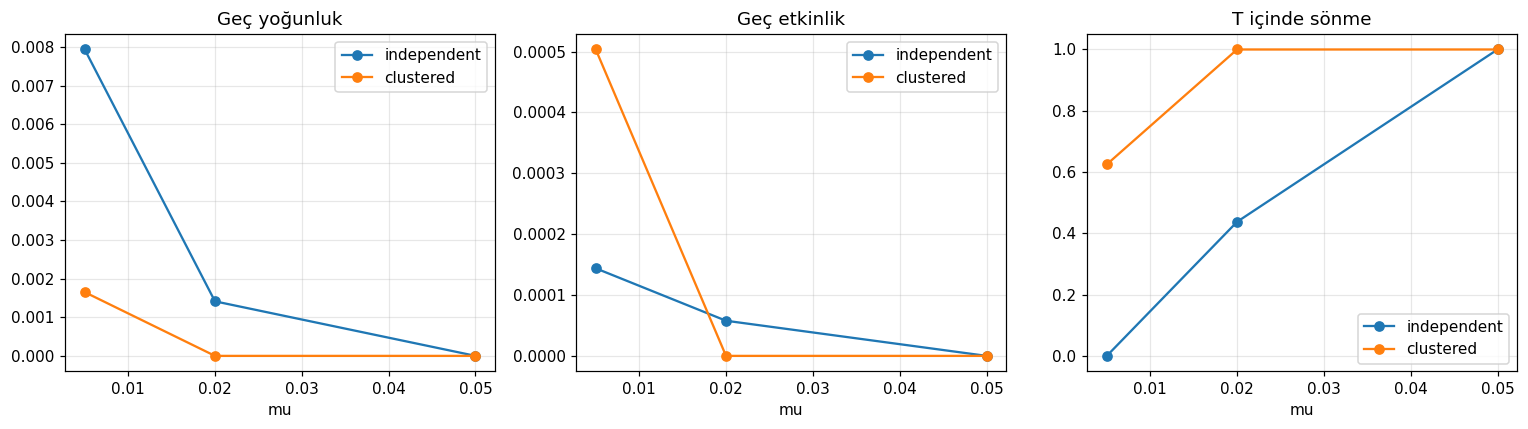

In [11]:
if comparison:
    fig, axes = plt.subplots(1, 3, figsize=(14,4))
    for name in ('independent', 'clustered'):
        rho = [np.mean([r['rho'] for r in comparison[mu][name]]) for mu in corr_mu_values]
        act = [np.mean([r['activity'] for r in comparison[mu][name]]) for mu in corr_mu_values]
        ext = [np.mean([r['extinct'] for r in comparison[mu][name]]) for mu in corr_mu_values]
        for ax, values, title in zip(axes, (rho, act, ext), ('Geç yoğunluk','Geç etkinlik','T içinde sönme')):
            ax.plot(corr_mu_values, values, 'o-', label=name)
            ax.set(xlabel='mu', title=title)
    for ax in axes:
        ax.legend()
        ax.grid(alpha=.3)
    plt.tight_layout()
    plt.show()

### Bağımsız ve kümelenmiş modellerin ilk karşılaştırması

$L=60$, $T=1.000$ ve $M=16$ için $\mu=0,005$ değerinde bağımsız modelde sönme görülmezken kümelenmiş modelde yaklaşık yüzde 62,5 sönme görüldü. $\mu=0,02$ için bağımsız modelde sönme oranı yüzde 43,75, kümelenmiş modelde yüzde 100 oldu. $\mu=0,05$ için iki model de bütün tekrarlarda söndü.

Aynı ölüm olasılığı, uzun vadede aynı sistem davranışını garanti etmiyor. Bunun nedeni yerel komşuluk ilişkilerinin ölümlerin nerede gerçekleştiğine duyarlı olması olabilir. Bu yorumu kesin neden olarak değil, sınanacak açıklama olarak görüyorum.


## 9. İlk sonuçlardan çıkardıklarım

Kümelenmiş ölüm ve bağımsız ölüm aynı `μ` değerinde farklı sonuçlar verebiliyor. Özellikle düşük ölüm olasılıklarında aradaki fark daha belirgin görünüyor. Yine de tek bir `μ` ve `L` ile genel sonuca varmak istemedim.

Bir sonraki adımda ızgarayı büyütüp gözlem süresini uzattım. Bu çalışmada faz geçişi veya kritik nokta bulduğumu söyleyemem. Bunun için daha fazla parametre ve literatür araştırması gerekiyor.

## 10. L değerini artırma

Izgara boyutunun etkisini de görmek istedim. `L` karenin bir kenarı. Örneğin `L = 200` için toplam 40.000 hücre var.

Önce `L = 60, 80, 100, 200` değerleriyle 1.000 karelik deney yaptım. Her boyutta 20 tekrar kullandım. Ölüm olasılığı `μ = 0,02`, kümelenme ölçeği de `σ = 2`.

L büyüdükçe hesaplama da büyüdüğü için komşu sayısını hesaplayan bölümü hızlandırdım. Yoğunluk ve etkinlik dizilerini sakladım, bütün ızgaraları saklamadım.

In [12]:
import numpy as np, time, csv
from scipy.ndimage import gaussian_filter
from scipy.special import ndtr
try:
    from numba import njit
except ImportError:
    def njit(*args, **kwargs):
        def decorator(func):
            return func
        return decorator
from pathlib import Path
OUT=Path('.')
@njit(cache=False)
def life_step(g):
    L=g.shape[0]
    out=np.zeros_like(g)
    for i in range(L):
        for j in range(L):
            count=0
            for di in (-1,0,1):
                for dj in (-1,0,1):
                    if di!=0 or dj!=0:
                        count+=g[(i+di)%L,(j+dj)%L]
            if count==3 or (g[i,j]==1 and count==2): out[i,j]=1
    return out

def trial(L,T,mu,sigma,seed,p0=.35,window=200,death_seed=None):
    g=(np.random.default_rng(seed).random((L,L))<p0).astype(np.uint8)
    rng=np.random.default_rng(seed+100000 if death_seed is None else death_seed)
    densities=np.zeros(T)
    activities=np.zeros(T-1)
    densities[0]=g.mean()
    tau=-1
    # Kümelenme ölçeği bütün L değerlerinde aynı.
    if sigma>0:
        kernel_point=np.zeros((L,L))
        kernel_point[0,0]=1
        k=gaussian_filter(kernel_point,sigma=sigma,mode='wrap')
        normalization=np.sqrt(np.sum(k*k))
    for t in range(1,T):
        ng=life_step(g)
        if mu==1: ng.fill(0)
        elif mu>0:
            if sigma==0:mask=rng.random((L,L))<mu
            else:
                z=gaussian_filter(rng.standard_normal((L,L)),sigma=sigma,mode='wrap') / normalization
                mask=ndtr(z)<mu
            ng[mask]=0
        activities[t-1]=np.count_nonzero(g!=ng)/(L*L)
        densities[t]=ng.mean()
        if not ng.any():
            tau=t
            break
        g=ng
    return dict(rho=float(densities[-window:].mean()),activity=float(activities[-window:].mean()),extinct=int(tau!=-1),tau=tau,densities=densities,activities=activities)

def run(T=1000,R=5,mu=.02,sigma=2.0):
    # Numba fonksiyonunu ilk kez çalıştırıyorum.
    life_step(np.ones((4,4),dtype=np.uint8))
    rows=[]
    curves={}
    begin=time.time()
    for L in [60,80,100,200]:
        for rep in range(R):
            initial_seed=27000+L*100+rep
            for model,s in [('Bağımsız',0),('Kümelenmiş',sigma)]:
                res=trial(L,T,mu,s,initial_seed,death_seed=initial_seed+ (100000 if s==0 else 900000))
                rows.append({k:res[k] for k in ['rho','activity','extinct','tau']}|{'L':L,'tekrar':rep+1,'model':model,'T':T,'mu':mu,'sigma':s})
                curves[(L,model,rep)]=(res['densities'],res['activities'])
        print('L=',L,'tamamlandı, saniye:',round(time.time()-begin,1),flush=True)
    with open(OUT/'L_boyut_deney_sonuclari.csv','w',newline='',encoding='utf-8-sig') as f:
        w=csv.DictWriter(f,fieldnames=rows[0].keys())
        w.writeheader()
        w.writerows(rows)
    return rows,curves



L= 60 tamamlandı, saniye: 2.4


L= 80 tamamlandı, saniye: 6.6


L= 100 tamamlandı, saniye: 13.0


L= 200 tamamlandı, saniye: 41.9


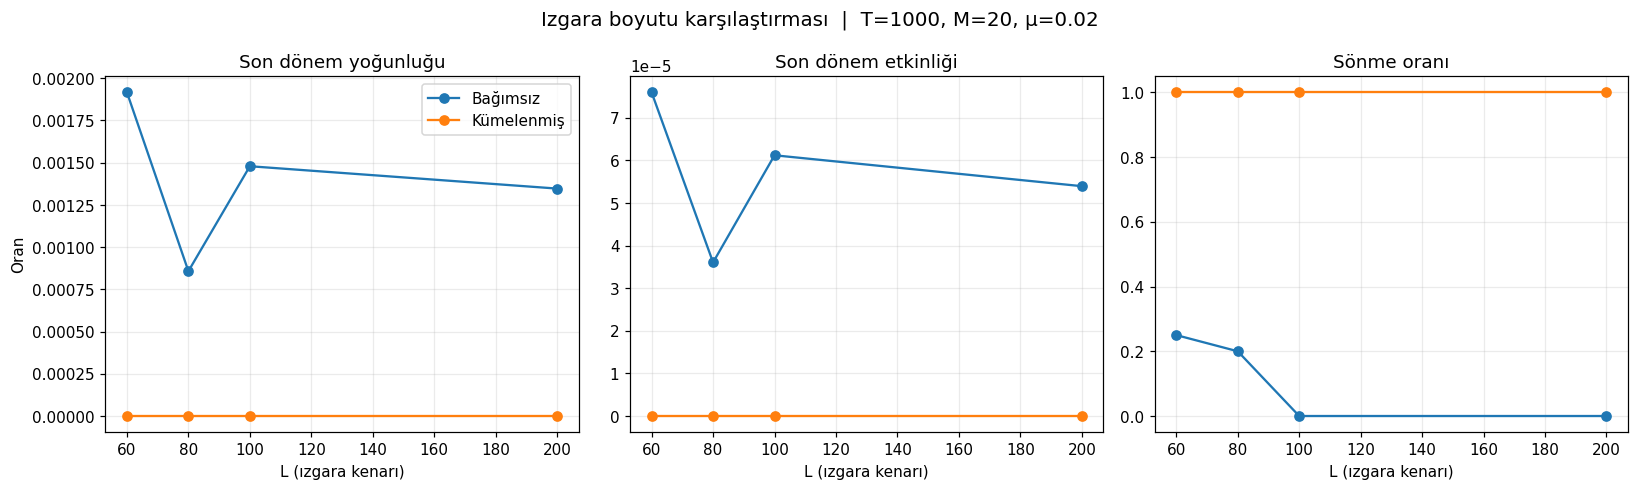

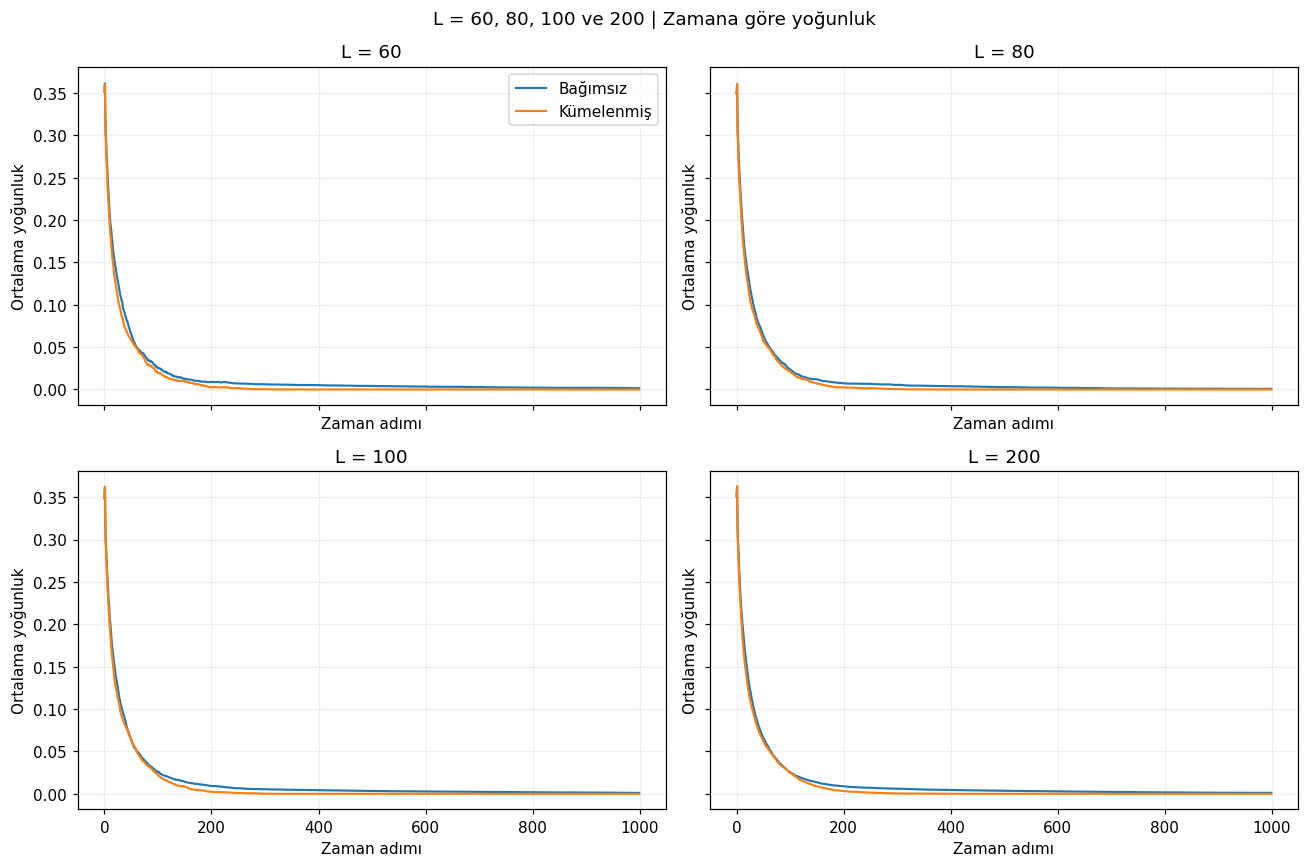

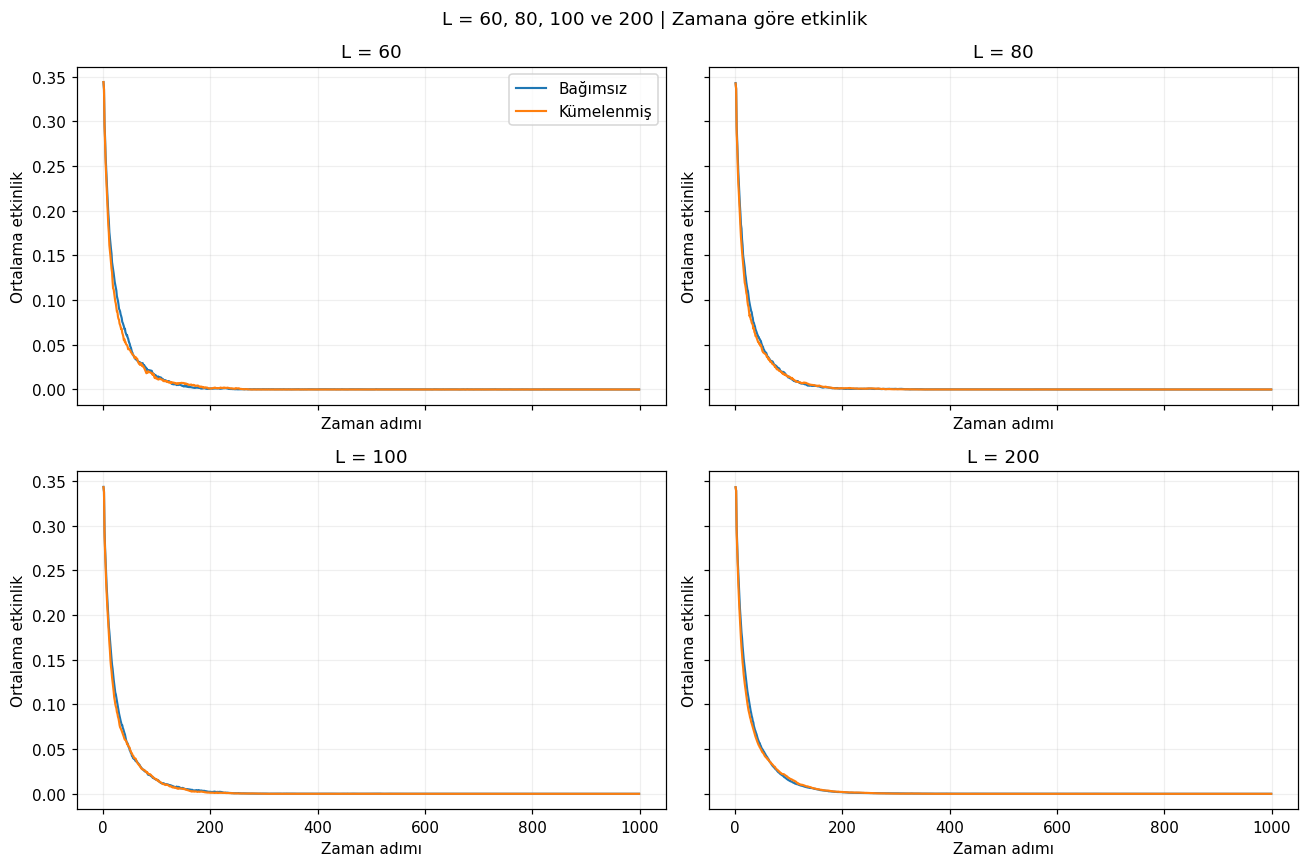

L karşılaştırması tamamlandı.


In [13]:

import matplotlib.pyplot as plt
T=1000
R=20
mu=.02
sigma=2.0
rows,curves=run(T,R,mu,sigma)
plt.rcParams['font.family']='DejaVu Sans'
fig,axs=plt.subplots(1,3,figsize=(15,4.5))
metrics=[('rho','Son dönem yoğunluğu'),('activity','Son dönem etkinliği'),('extinct','Sönme oranı')]
for model in ['Bağımsız','Kümelenmiş']:
    for ax,(key,title) in zip(axs,metrics):
        means=[np.mean([r[key] for r in rows if r['L']==L and r['model']==model]) for L in [60,80,100,200]]
        ax.plot([60,80,100,200],means,marker='o',label=model)
        ax.set_title(title)
        ax.set_xlabel('L (ızgara kenarı)')
        ax.grid(alpha=.25)
axs[0].set_ylabel('Oran')
axs[2].set_ylim(-.05,1.05)
axs[0].legend()
fig.suptitle(f'Izgara boyutu karşılaştırması  |  T={T}, M={R}, μ={mu}',fontsize=13)
fig.tight_layout()
fig.savefig(OUT/'L_60_80_100_200_karsilastirma.png',dpi=170)
plt.show()
fig,axs=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for ax,L in zip(axs.flat,[60,80,100,200]):
    for model in ['Bağımsız','Kümelenmiş']:
        y=np.mean([curves[(L,model,rep)][0] for rep in range(R)],axis=0)
        ax.plot(range(T),y,label=model,lw=1.4)
    ax.set_title(f'L = {L}')
    ax.set_xlabel('Zaman adımı')
    ax.set_ylabel('Ortalama yoğunluk')
    ax.grid(alpha=.2)
axs[0,0].legend()
fig.suptitle('L = 60, 80, 100 ve 200 | Zamana göre yoğunluk')
fig.tight_layout()
fig.savefig(OUT/'L_boyut_zaman_grafikleri.png',dpi=170)
plt.show()
fig,axs=plt.subplots(2,2,figsize=(12,8),sharex=True,sharey=True)
for ax,L in zip(axs.flat,[60,80,100,200]):
    for model in ['Bağımsız','Kümelenmiş']:
        y=np.mean([curves[(L,model,rep)][1] for rep in range(R)],axis=0)
        ax.plot(range(1,T),y,label=model,lw=1.4)
    ax.set_title(f'L = {L}')
    ax.set_xlabel('Zaman adımı')
    ax.set_ylabel('Ortalama etkinlik')
    ax.grid(alpha=.2)
axs[0,0].legend()
fig.suptitle('L = 60, 80, 100 ve 200 | Zamana göre etkinlik')
fig.tight_layout()
fig.savefig(OUT/'L_boyut_etkinlik_grafikleri.png',dpi=170)
plt.show()
print('L karşılaştırması tamamlandı.')

### 10.1 L karşılaştırmasının grafikleri

Bu grafiklerde 1.000 kare sonunda iki modelin yoğunluk, etkinlik ve sönme oranlarını karşılaştırdım.

Burada kullandığım `numba` kuruluysa komşuluk hesabı daha hızlı çalışıyor. Kurulu olmasa da hesaplama yapılabiliyor, fakat büyük ızgaralar daha fazla zaman alabilir.

### 10.2 İlk L deneyinden sonra

Özellikle büyük ızgaralarda 1.000 kare sonunda hâlâ canlı hücreler kalabiliyor. Bu yüzden 1.000 kareyle yetinmeyip gözlemi 3.000 adıma uzatmaya karar verdim.

Belirlenen süre içinde sönmeyen sistemlerin daha sonra sönüp sönmeyeceğini bu deneyden bilemiyorum.

## 11. 3.000 adımlık deney

Bu kez dört L değeri (`60, 80, 100, 200`) ve üç ölüm olasılığı (`0,005`, `0,02`, `0,05`) kullandım. Her koşulu 20 kez tekrarladım. İki modelle birlikte toplam 480 simülasyon oldu.

Başlangıç ızgaralarını eşleştirdim. Kümelenmiş modelde `σ = 2` kullandım. Sönmenin 1.000, 2.000 ve 3.000. adımlarda olup olmadığına da baktım. Böylece sadece son durumu değil, zamana bağlı farkı da görebiliyorum.

### Zaman adımı sayısının kullanımı

İlk alıştırmalardaki `simulate_noisy_life` fonksiyonunda `steps` başlangıç karesini de içeriyor. Uzun deneydeki `uzun_deney` fonksiyonunda ise 3.000 güncelleme yapılıyor. Burada başlangıç durumu dahil toplam 3.001 yoğunluk kaydı var. İki bölümün zaman sayımı bu nedenle aynı değil.


In [14]:
# 3.000 adımlık karşılaştırma
import numpy as np
import pandas as pd
from scipy.ndimage import convolve, gaussian_filter
from scipy.special import ndtr

komsuluk = np.ones((3, 3), dtype=np.uint8)
komsuluk[1, 1] = 0

def uzun_deney(L, mu, sigma, baslangic_tohumu, olum_tohumu):
    g = (np.random.default_rng(baslangic_tohumu).random((L, L)) < 0.35).astype(np.uint8)
    rng = np.random.default_rng(olum_tohumu)
    toplam_adim = 3000
    yogunluk = np.zeros(toplam_adim + 1)
    etkinlik = np.zeros(toplam_adim)
    yogunluk[0] = g.mean()
    sonme = -1
    if sigma > 0:
        merkez = np.zeros((L, L))
        merkez[0, 0] = 1
        cekirdek = gaussian_filter(merkez, sigma, mode='wrap')
        olcek = np.sqrt(np.sum(cekirdek ** 2))
    for t in range(1, toplam_adim + 1):
        komsu = convolve(g, komsuluk, mode='wrap')
        yeni = ((komsu == 3) | ((g == 1) & (komsu == 2))).astype(np.uint8)
        if sigma == 0:
            mask = rng.random((L, L)) < mu
        else:
            alan = gaussian_filter(rng.standard_normal((L, L)), sigma, mode='wrap') / olcek
            mask = ndtr(alan) < mu
        yeni[mask] = 0
        etkinlik[t - 1] = np.count_nonzero(g != yeni) / (L * L)
        yogunluk[t] = yeni.mean()
        if not yeni.any():
            sonme = t
            break
        g = yeni
    return sonme, float(yogunluk[-300:].mean()), float(etkinlik[-300:].mean())

L_degerleri = [60, 80, 100, 200]
mu_degerleri = [0.005, 0.02, 0.05]
tekrar_sayisi = 20
sonuclar_3000 = []
for L in L_degerleri:
    for mu in mu_degerleri:
        for tekrar in range(tekrar_sayisi):
            baslangic = 620000 + L * 1000 + tekrar
            for model, sigma in [('Bağımsız', 0.0), ('Kümelenmiş', 2.0)]:
                olum_tohumu = baslangic + (10000000 if sigma == 0 else 20000000) + int(mu * 1000000)
                tau, rho, activity = uzun_deney(L, mu, sigma, baslangic, olum_tohumu)
                satir = {'L': L, 'mu': mu, 'tekrar': tekrar + 1, 'model': model,
                         'tau': tau, 'son_yogunluk': rho, 'son_etkinlik': activity}
                for zaman in [1000, 2000, 3000]:
                    satir[f'sondu_{zaman}'] = int(tau != -1 and tau <= zaman)
                sonuclar_3000.append(satir)
        print('Tamamlandı:', 'L =', L, 'μ =', mu)
tablo_3000 = pd.DataFrame(sonuclar_3000)
tablo_3000.to_csv('stochastic_3000_tum_480_simulasyon.csv', index=False, encoding='utf-8-sig')
print('Toplam simülasyon:', len(tablo_3000))

Tüm 12 koşul tamamlandı.
Toplam simülasyon: 480


### 11.1 Grafikler

Aşağıdaki grafikler 480 simülasyonun sonuçlarından hesaplanıyor.

**L değerine göre 3.000. adımda sönme oranı**

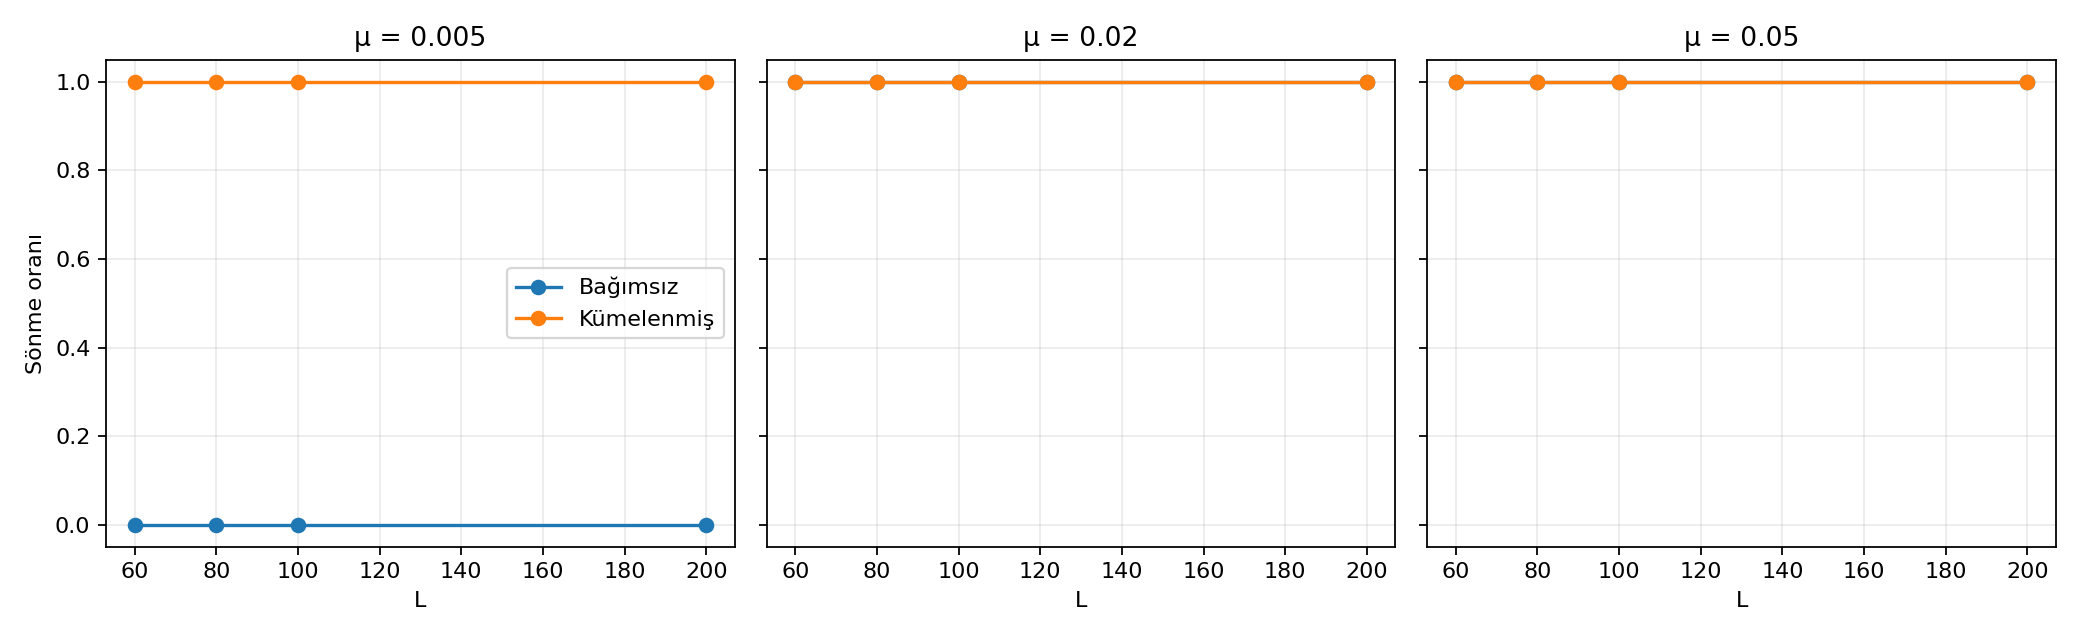

In [15]:
# 3.000. adımdaki sönme oranları
fig, eksenler = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for eksen, mu in zip(eksenler, mu_degerleri):
    veriler = tablo_3000[tablo_3000['mu'] == mu]
    for model in ['Bağımsız', 'Kümelenmiş']:
        secim = veriler[veriler['model'] == model]
        oranlar = secim.groupby('L')['sondu_3000'].mean()
        eksen.plot(oranlar.index, oranlar.values, 'o-', label=model)
    eksen.set_title(f'μ = {mu}')
    eksen.set_xlabel('L')
    eksen.set_ylim(-0.05, 1.05)
    eksen.grid(alpha=0.25)
eksenler[0].set_ylabel('Sönme oranı')
eksenler[0].legend()
fig.tight_layout()
fig.savefig('stochastic_3000_L_sonme.png', dpi=160)
plt.show()

**1.000, 2.000 ve 3.000. adımlarda sönme oranı**

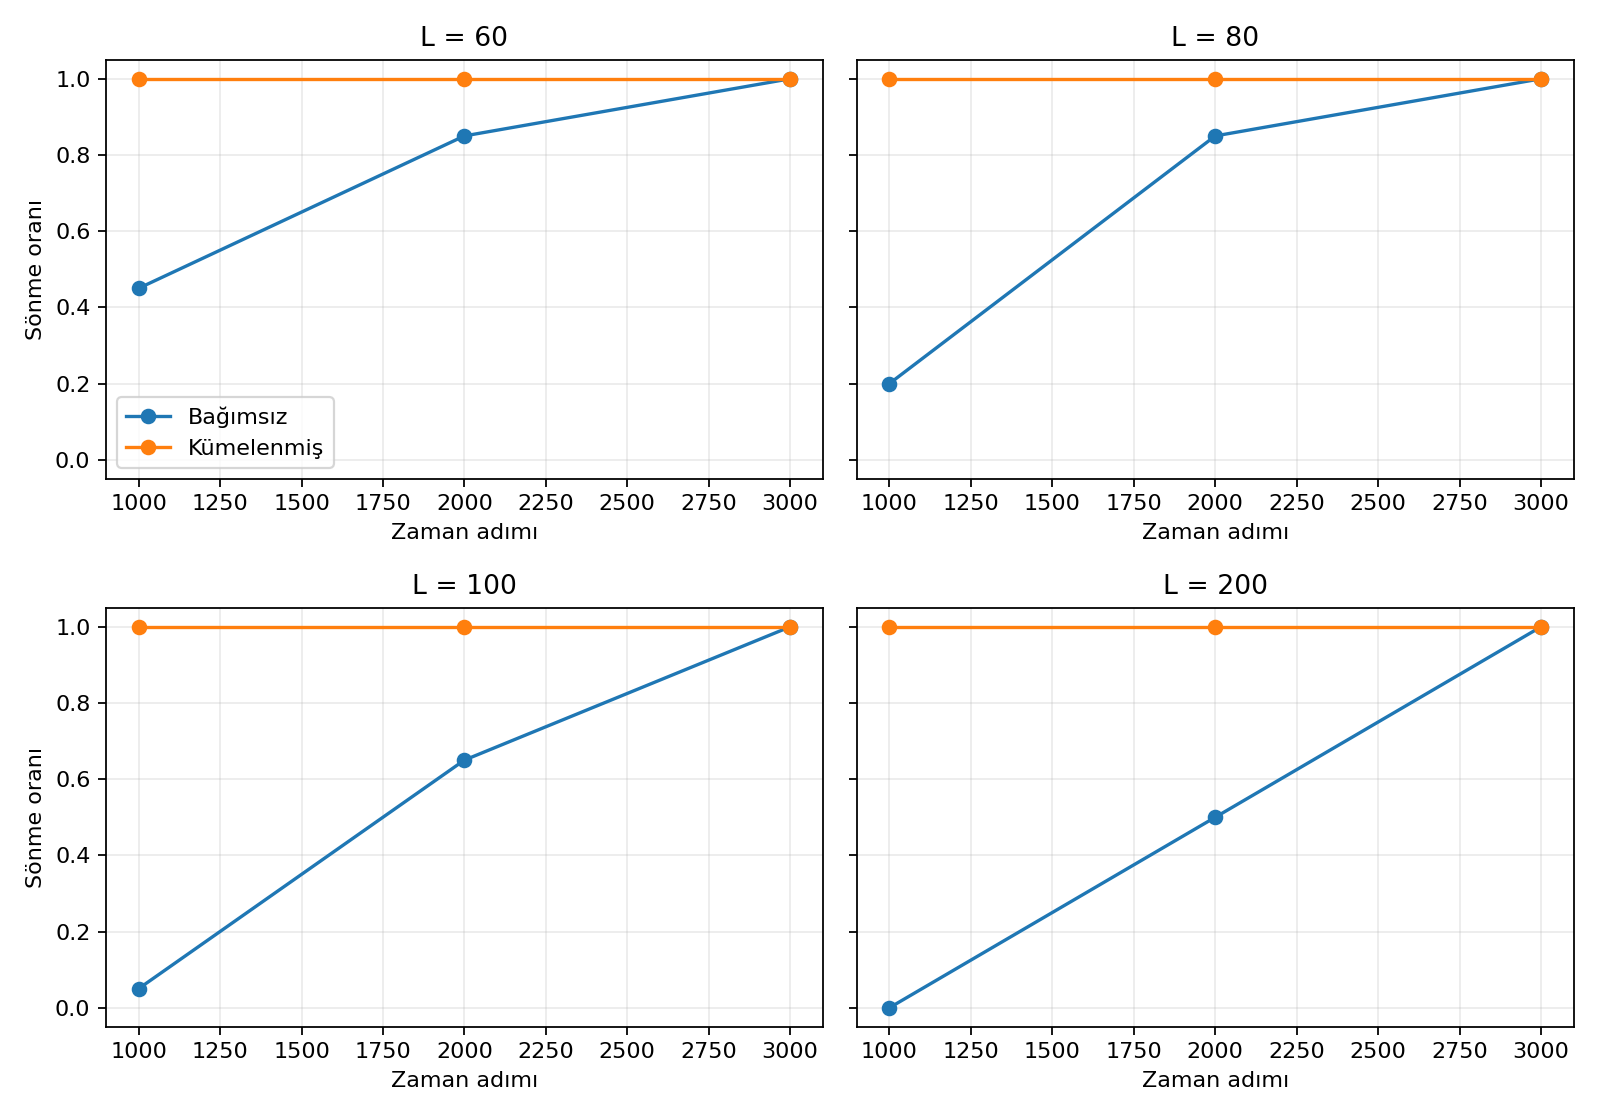

In [15]:
# μ = 0,02 için zamana göre sönme oranı
fig, eksenler = plt.subplots(2, 2, figsize=(10, 7), sharey=True)
zamanlar = [1000, 2000, 3000]
for eksen, L in zip(eksenler.flat, L_degerleri):
    veriler = tablo_3000[(tablo_3000['L'] == L) & (tablo_3000['mu'] == 0.02)]
    for model in ['Bağımsız', 'Kümelenmiş']:
        secim = veriler[veriler['model'] == model]
        oranlar = [secim[f'sondu_{t}'].mean() for t in zamanlar]
        eksen.plot(zamanlar, oranlar, 'o-', label=model)
    eksen.set_title(f'L = {L}')
    eksen.set_xlabel('Zaman adımı')
    eksen.set_ylim(-0.05, 1.05)
    eksen.grid(alpha=0.25)
eksenler[0, 0].set_ylabel('Sönme oranı')
eksenler[1, 0].set_ylabel('Sönme oranı')
eksenler[0, 0].legend()
fig.tight_layout()
fig.savefig('stochastic_3000_sonme_zaman.png', dpi=160)
plt.show()

**Son 300 adımdaki ortalama yoğunluk ve etkinlik**

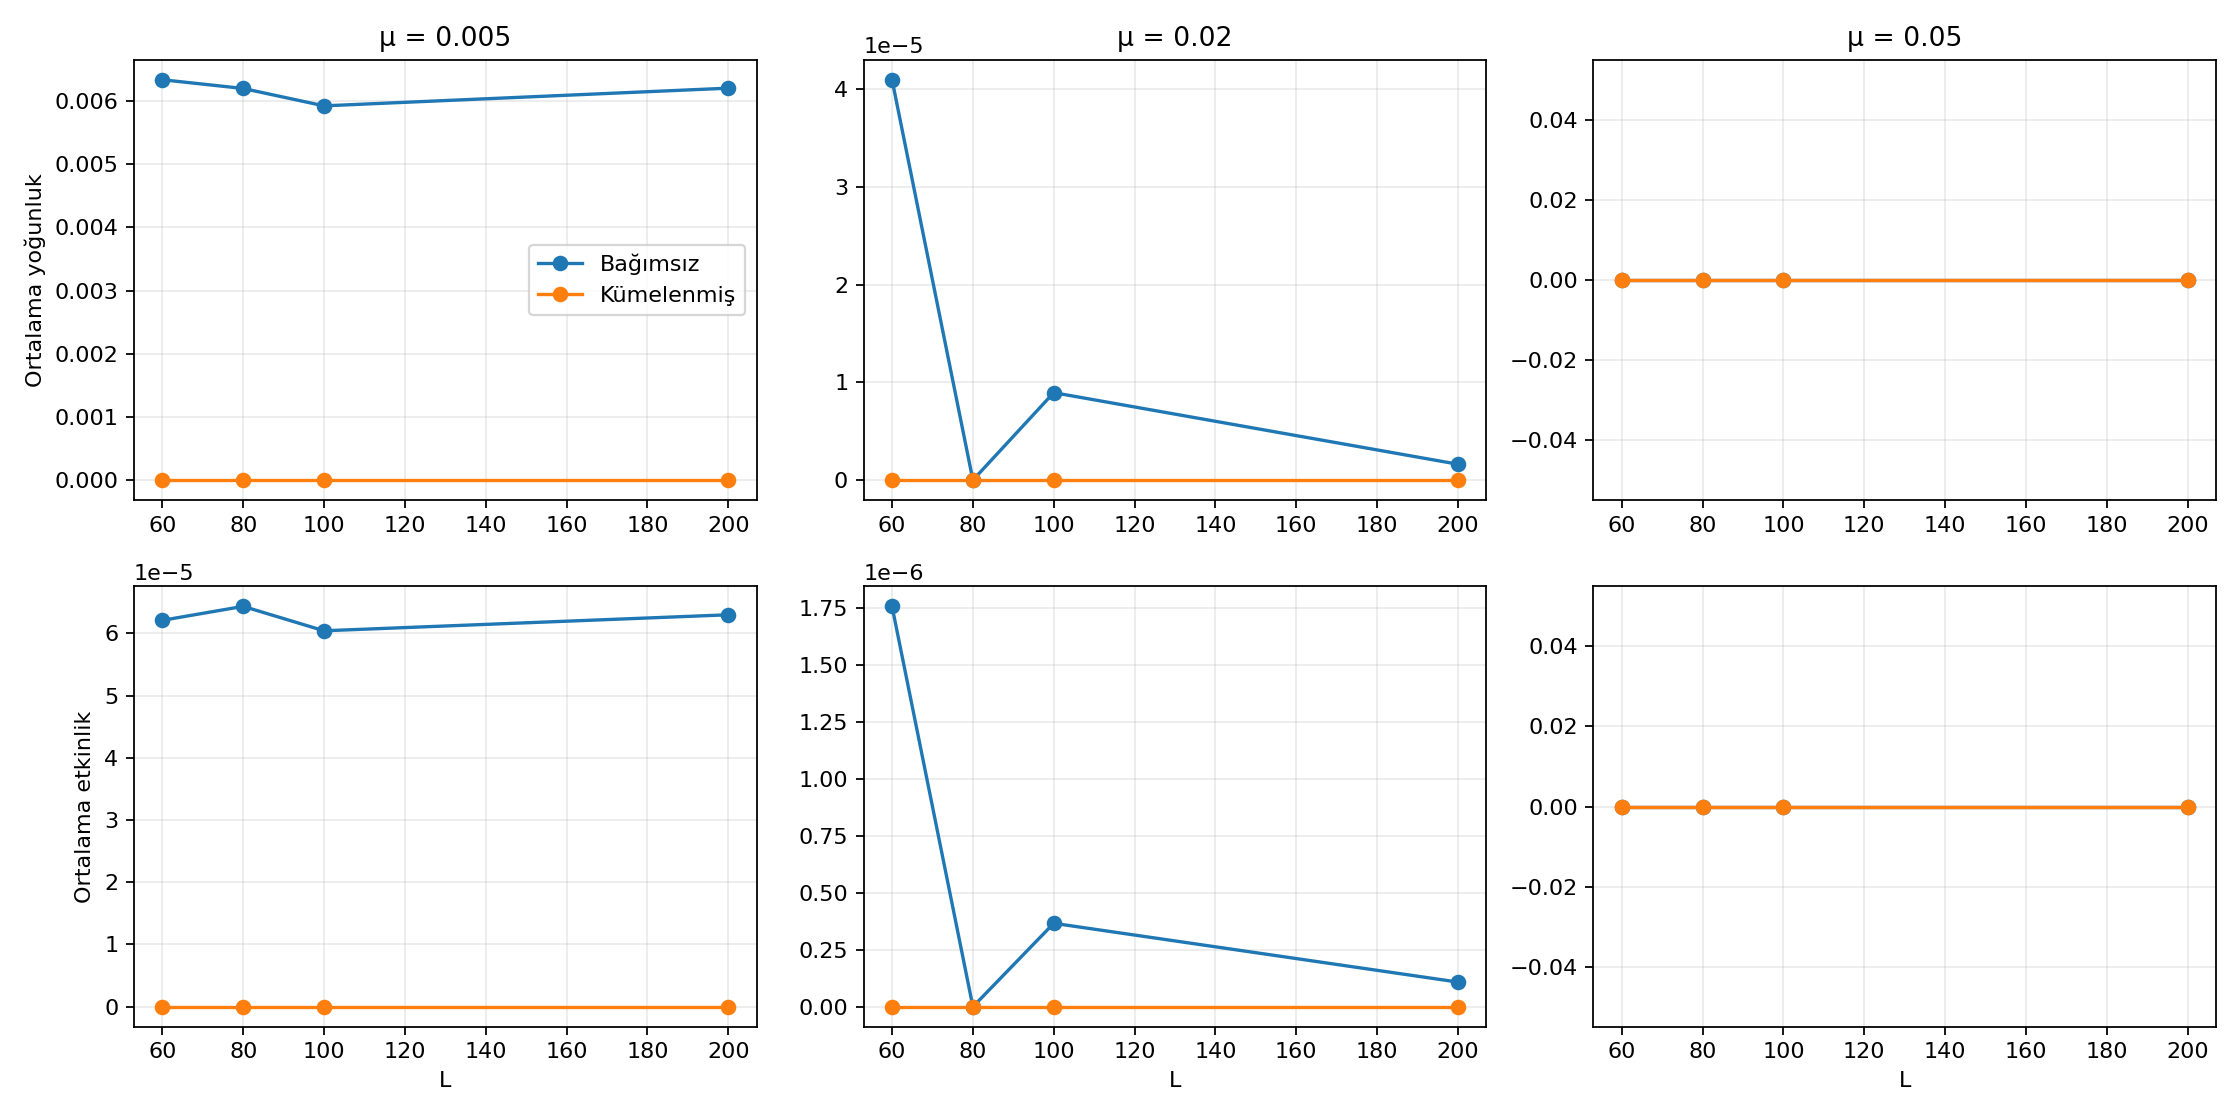

In [15]:
# Son 300 adımdaki yoğunluk ve etkinlik
fig, eksenler = plt.subplots(2, 3, figsize=(14, 7))
for j, mu in enumerate(mu_degerleri):
    veriler = tablo_3000[tablo_3000['mu'] == mu]
    for model in ['Bağımsız', 'Kümelenmiş']:
        secim = veriler[veriler['model'] == model]
        for i, sutun in enumerate(['son_yogunluk', 'son_etkinlik']):
            ortalama = secim.groupby('L')[sutun].mean()
            eksenler[i, j].plot(ortalama.index, ortalama.values, 'o-', label=model)
    eksenler[0, j].set_title(f'μ = {mu}')
    eksenler[1, j].set_xlabel('L')
    for i in range(2):
        eksenler[i, j].grid(alpha=0.25)
eksenler[0, 0].set_ylabel('Ortalama yoğunluk')
eksenler[1, 0].set_ylabel('Ortalama etkinlik')
eksenler[0, 0].legend()
fig.tight_layout()
fig.savefig('stochastic_3000_yogunluk_etkinlik.png', dpi=160)
plt.show()

### 11.2 Sonuç

`μ = 0,005` için bağımsız model 3.000 adım içinde hiçbir tekrarda tamamen sönmedi. Kümelenmiş model ise denediğim bütün L değerlerinde 20 tekrarın tamamında söndü.

`μ = 0,02` için de 3.000. adıma gelindiğinde iki modelin bütün tekrarları sönmüştü. Ancak bağımsız modelde özellikle büyük L değerlerinde bu daha geç gerçekleşti. `μ = 0,05` değerinde iki model de daha erken söndü.

Şu anki sonuçlarda ölümlerin uzayda nasıl dağıldığı önemli görünüyor. Yine de bunlar yalnızca seçtiğim parametreler ve 3.000 adımlık gözlem süresi için geçerli. Daha sonra `σ` değerini değiştirerek kümelenme boyutunun etkisine de bakmak istiyorum.

## 12. Sonuç ve 7. hafta araştırma sorusu

Bu çalışmada önce standart B3/S23 güncellemesini, ardından rastgele ölümü uyguladım. $\mu=0$ değeri standart Game of Life'ı temsil ediyor.

Ana deneyden sonra aynı ölüm olasılığı altında bağımsız ve uzaysal olarak ilintili ölümleri karşılaştırdım. Genişletilmiş deneyde $L=60,80,100,200$, $\mu=0,005,0,02,0,05$, $T=3.000$ ve her koşul için $M=20$ kullandım. Başlangıç canlılık olasılığı $p_0=0,35$ idi. Böylece toplam 480 simülasyon çalıştırdım.

**Ölçtüğüm sonuçlar:**

- $\mu=0,005$ için bütün L değerlerinde bağımsız model 20 tekrarın hiçbirinde 3.000 adımda sönmedi. Kümelenmiş model her L değerinde 20 tekrarın tamamında söndü.
- $\mu=0,02$ için L = 200 koşulunda bağımsız model 1.000 adımda 0/20, 2.000 adımda 10/20 ve 3.000 adımda 20/20 sönme gösterdi.
- $\mu=0,05$ için iki model de bütün L değerlerinde 3.000 adım dolmadan söndü.

Bu bulgular, yalnızca ölüm olasılığının değil, ölümlerin uzaysal dağılımının da sistemin sönme davranışını etkileyebileceğini gösteriyor. Gaussyen filtrenin neden böyle bir etki oluşturduğunu daha iyi açıklamak için teorik analiz ve benzer çalışmalarla karşılaştırma gerekiyor.

**Sınırlamalar:** Sonlu boyut, sonlu süre, yalnızca seçilmiş ölüm olasılıkları, her koşulda 20 tekrar ve kümelenmiş modelde tek bir filtre genişliği kullandım. Bir deney 3.000 adımda sönmediyse yalnızca bu sürede canlı kaldığını biliyorum. Bunu sonsuz süre yaşamakla eşitlemiyorum. Ayrıca deneylerin tek başına bir faz geçişini kanıtlamadığının farkındayım.

### 7. hafta için araştırma sorum

**Filtrenin genişliği değiştiğinde sönme süresi nasıl değişiyor?**

Bunu incelemek için $\sigma=1,2,4$ değerlerini karşılaştırmayı düşünüyorum. Diğer parametreleri, özellikle $L$, $\mu$, $p_0$, $T$ ve tekrar sayısını sabit tutup sönme oranını ve sönme zamanını ölçebilirim. Bu bölüm henüz yapılmış bir deney değil, sonraki hafta için önerim.

### AI kullanımı

Bazı kod bölümlerinin hazırlanması, Gaussyen filtreli model ve çok sayıda simülasyonun daha hızlı çalıştırılması için AI desteği aldım. Ayrıntıları `AI_NOTES.md` dosyasında belirttim.

### Teslim kontrolü

- [x] Beş alıştırmanın temel testleri geçti.
- [x] Pilot, ana tarama ve kontrol deneyi çalıştırıldı.
- [x] Uzun gözlem ve farklı L değerleriyle sağlamlık kontrolü yapıldı.
- [x] Sonuçların önemli sayısal değerleri ve grafikler kaydedildi.
- [x] Modelin sınırlamaları ve 7. hafta araştırma sorusu yazıldı.
- [ ] Güncel sürüm Colab'da baştan sona yeniden çalıştırılıp doğrulanacak.
